In [20]:
import pandas as pd

df = pd.read_csv("aggregation.txt", sep="\t")

df.head()

# Abbiamo tre colonne, X|Y|Cluster di appartenenza

X = df.iloc[:,:2].values
y = df.iloc[:,2].values





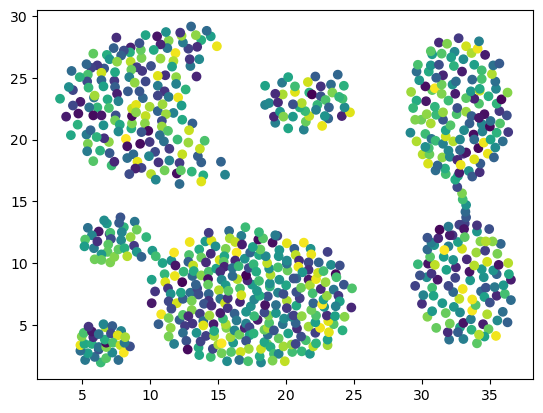

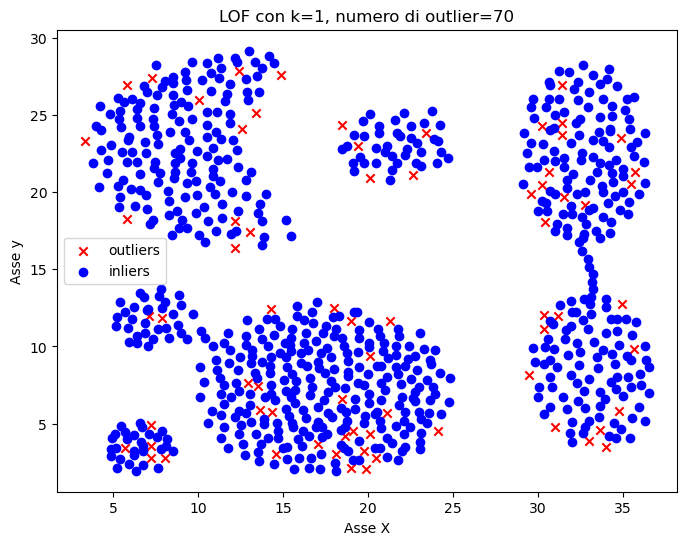

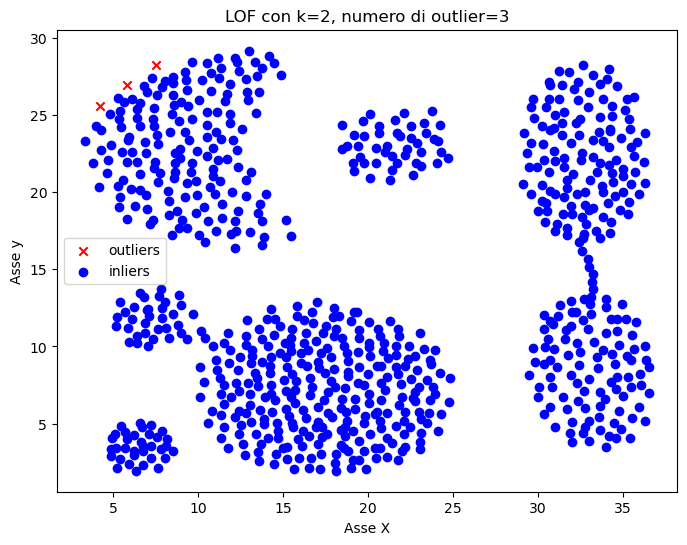

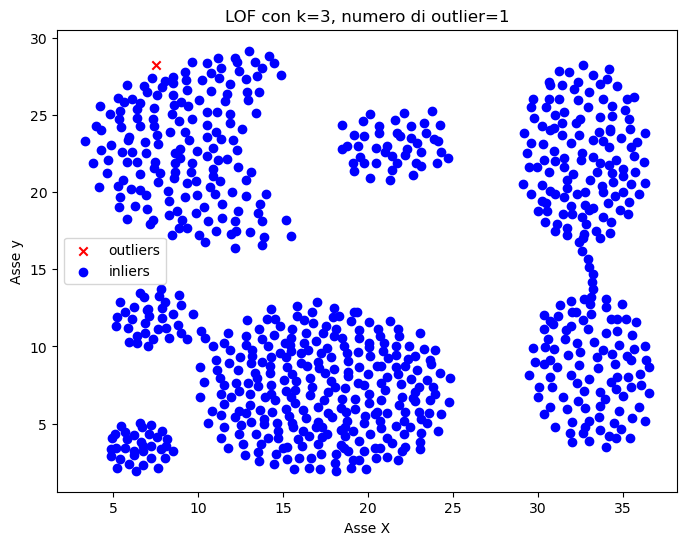

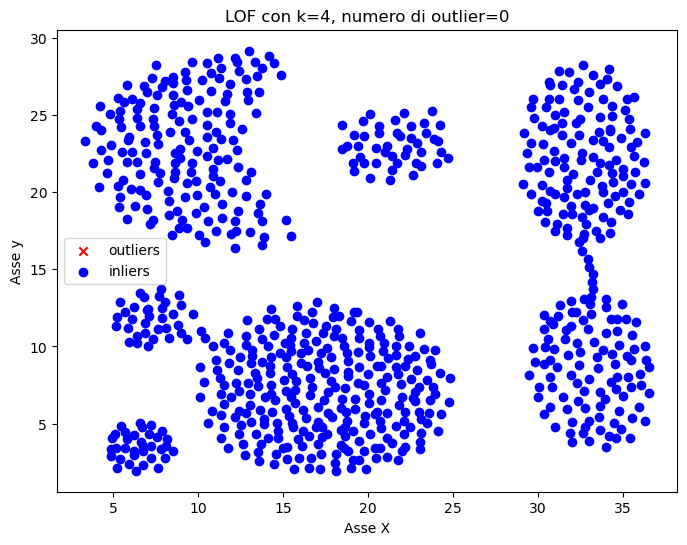

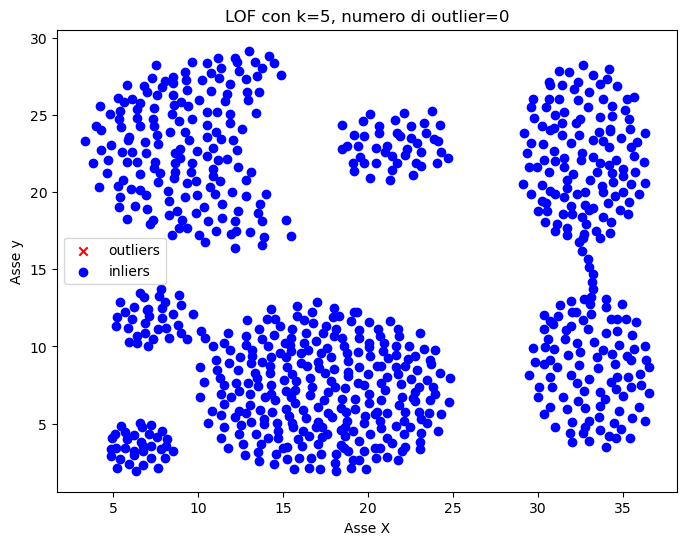

In [26]:
# Local Outlier Factor, indivuare gli outlier

from sklearn.neighbors import LocalOutlierFactor
import matplotlib.pyplot as plt
import numpy as np

n_neighbors = [1,2,3,4,5]
y_binary = np.where(y == -1,-1,1)

plt.scatter(X[:,0],X[:,1], cmap="viridis", c=np.random.rand(787))


for k in n_neighbors:
    plt.figure(figsize=(8,6))
    clf = LocalOutlierFactor(n_neighbors=k)
    pred = clf.fit_predict(X)
    pred_binary = np.where(pred == -1,-1, 1) # -1 outlier, 1 inlier
    num_outlier = (pred==-1).sum()
    plt.scatter(X[pred_binary == -1, 0], X[pred_binary == -1, 1], color='red', label="outliers", marker='x')
    plt.scatter(X[pred_binary == 1, 0], X[pred_binary == 1, 1], color='blue', label="inliers")

    plt.title(f"LOF con k={k}, numero di outlier={num_outlier}")
    plt.xlabel("Asse X")
    plt.ylabel("Asse y")
    plt.legend()
    plt.show()



In [32]:
# Clustering con DBSCAN

from sklearn.cluster import DBSCAN

combinations = [
    {'eps': 0.2, 'min_samples' : 2},
    {'eps': 0.4, 'min_samples' : 3},
    {'eps': 0.5, 'min_samples' : 5},
]

scan_models = []
scan_model_predictions = []

for params in combinations:
    scan = DBSCAN(eps=params['eps'], min_samples=params['min_samples'])
    cluster_pred = scan.fit_predict(X)
    unique_clusters = set(cluster_pred) - {-1}
    n_clusters_trovati = len(unique_clusters)
    n_noises = (cluster_pred == -1).sum()

    scan_models.append([scan, cluster_pred])
    

    print(f"EPS:{params['eps']}, min_samples:{params['min_samples']}")
    print(f"Numero di cluster trovati:{n_clusters_trovati}, numero di rumori: {n_noises}")

EPS:0.2, min_samples:2
Numero di cluster trovati:6, numero di rumori: 775
EPS:0.4, min_samples:3
Numero di cluster trovati:5, numero di rumori: 772
EPS:0.5, min_samples:5
Numero di cluster trovati:0, numero di rumori: 787


In [30]:
from sklearn.mixture import GaussianMixture

initial_weights = np.ones(7) / 7
gm = GaussianMixture(n_components=7, weights_init=initial_weights, random_state=42) 
# weights_init si aspetta obbligatoriamente un array 
#(o una lista) di dimensione pari a n_components (nel tuo caso, 7 valori).
pred_gm = gm.fit_predict(X)


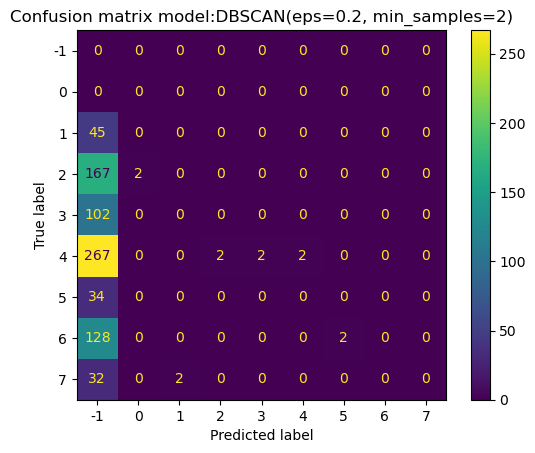

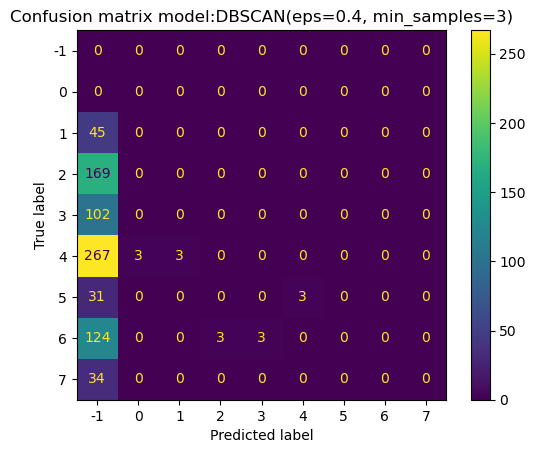

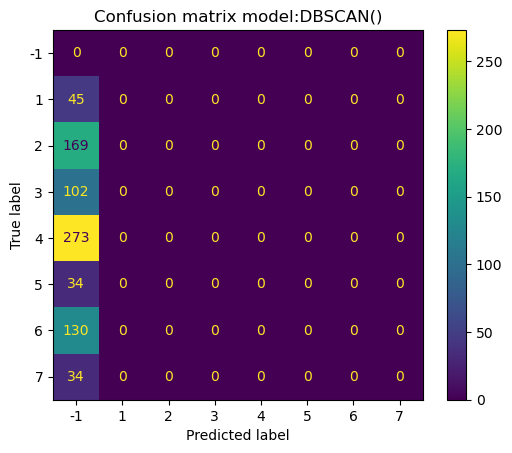

Text(0.5, 1.0, 'Matrice di confusione GaussianMixture:GaussianMixture(n_components=7, random_state=42,\n                weights_init=array([0.14285714, 0.14285714, 0.14285714, 0.14285714, 0.14285714,\n       0.14285714, 0.14285714]))')

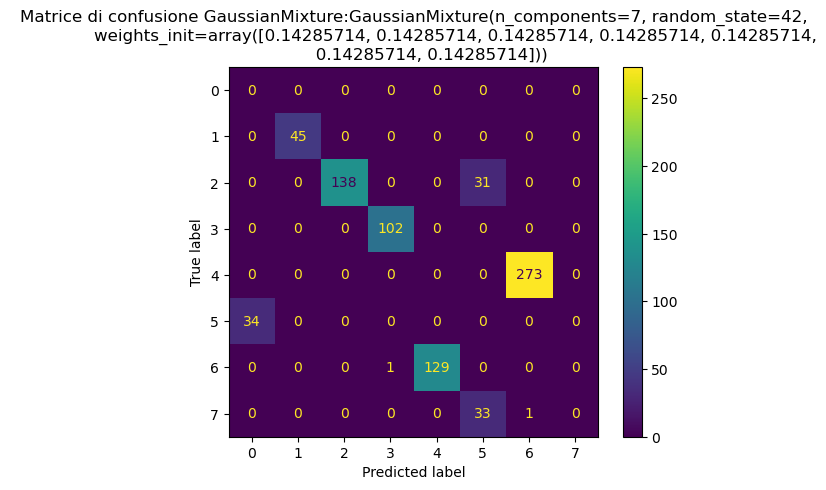

In [34]:
# Mostriamo la matrice di confusione di tutti gli algoritmi di clustering
from sklearn.metrics import ConfusionMatrixDisplay

for model, pred in scan_models:
    ConfusionMatrixDisplay.from_predictions(y, pred)
    plt.title(f"Confusion matrix model:{model}")
    plt.show()

ConfusionMatrixDisplay.from_predictions(y, pred_gm)
plt.title(f"Matrice di confusione GaussianMixture:{gm}")